# Explore sketch- and gene-based quantification in metagenomes with MIXED READS

This notebooks analyses metagenomes built with mixed reads from two genomes, ~4% divergent (ANI).

The reads are generated unevenly, with 90% from the first genome and 10% from the second genome.

The main takeaway from this is that the coverage curve-based quantitative estimator is sensitive to this mixture divergence in a way that it is not when the reads are from a "pure" mixture, and, in particular, that if you are using the minority strain genome as a reference, the results are crummy.

In [1]:
import polars as pl
import matplotlib.pyplot as plt

## Saturation curves when using different references

These look fine :).

In [2]:
# read k-mer collector's curve info
kmer_df = pl.read_csv('mixed_90_10/reads.isect.kmer_stats.csv')

Text(0.5, 1.0, 'Coverage saturation curves when using a single ref & mixed reads (90/10)')

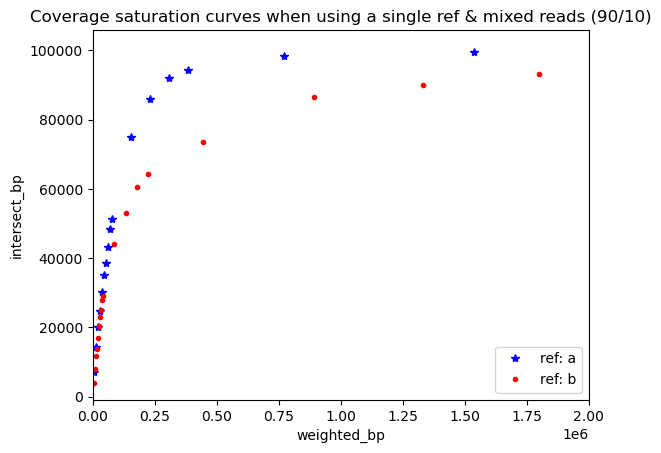

In [3]:
xx_df = kmer_df.filter(pl.col('species') == 'a')
yy_df = kmer_df.filter(pl.col('species') == 'b')
plt.plot(xx_df['weighted_bp'], xx_df['intersect_bp'], 'b*', label='ref: a')
plt.plot(yy_df['weighted_bp'], yy_df['intersect_bp'], 'r.', label='ref: b')

plt.xlim(0, 2e6)
plt.xlabel('weighted_bp')
plt.ylabel('intersect_bp')
plt.legend(loc='lower right')
plt.title('Coverage saturation curves when using a single ref & mixed reads (90/10)')

## Load combined coverage estimates

In [4]:
abund_df = (
    pl.read_csv('mixed_90_10/reads.isect.abund.csv')
    .with_columns(
        cov=pl.col('metag').str.split('-').list.get(1).cast(pl.Float32)
    )
)
abund_df['method'].unique()

method
str
"""gmm"""
"""composite_k"""
"""covcurve_round1"""
"""covcurve_round2"""
"""composite"""


## Compare k-mer abundance estimates vs different references for composite k-mer estimates

These results use the gaussian mixture model for mean abund > 10, which means they are reasonably accurate at high coverage... but the low coverage is systematically off, because it uses coverage curve estimation.

Not sure what's going on with the point at 30, could be statistical noise => error?

(0.0, 60.0)

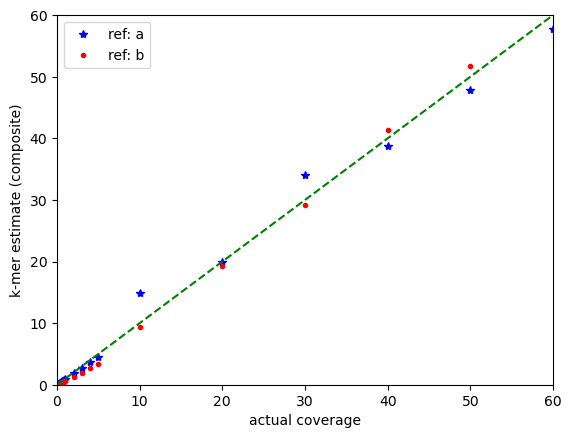

In [5]:
aa_df = abund_df.filter((pl.col('species') == 'a') & (pl.col('method') == 'composite'))
bb_df = abund_df.filter((pl.col('species') == 'b') & (pl.col('method') == 'composite'))

plt.plot(aa_df['cov'], aa_df['abund'], 'b*', label='ref: a')
plt.plot(bb_df['cov'], bb_df['abund'], 'r.', label='ref: b')
plt.plot([0, 100], [0, 100], 'g--')
plt.xlabel('actual coverage')
plt.ylabel('k-mer estimate (composite)')
plt.legend(loc='upper left')
plt.xlim(0, 60)
plt.ylim(0, 60)

## Compare k-mer abundance estimates vs different references for covcurve specifically

Looking at the coverage curve results specifically, we see the systematic error due to mixed reads pop up quite clearly.

Text(0.5, 1.0, 'coverage curve-based k-mer estimates only, for 90 a/10 b reads.')

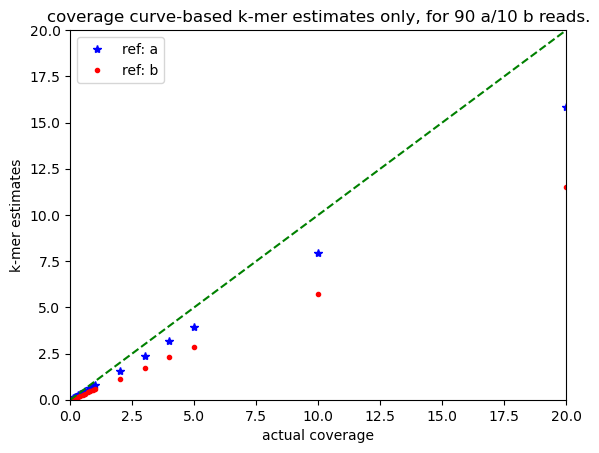

In [6]:
aa_df = abund_df.filter((pl.col('species') == 'a') & (pl.col('method') == 'covcurve_round2'))
bb_df = abund_df.filter((pl.col('species') == 'b') & (pl.col('method') == 'covcurve_round2'))

plt.plot(aa_df['cov'], aa_df['abund'], 'b*', label='ref: a')
plt.plot(bb_df['cov'], bb_df['abund'], 'r.', label='ref: b')
plt.xlim(0, 20)
plt.ylim(0, 20)
plt.plot([0, 100], [0, 100], 'g--')

plt.xlabel('actual coverage')
plt.ylabel('k-mer estimates')
plt.legend(loc='upper left')
plt.title('coverage curve-based k-mer estimates only, for 90 a/10 b reads.')